# Modelos que deciden en lugar de escribir

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | En la unidad 013 le pedimos a un modelo de lenguaje una salida con forma fija y la validamos; en la 015 el agente decidía qué herramienta usar escribiendo texto. Muchas veces el programa no necesita un texto, sino **una decisión entre opciones conocidas**: a qué área va un mensaje, si una reseña habla bien de la fotografía. |
| **Producto** | Una pregunta con opciones respondida por Julia-1, la cuenta que convierte puntajes en probabilidades hecha a mano, una compuerta que decide cuándo actuar y cuándo pasarle el caso a una persona, y una comparación con un modelo de lenguaje. |
| **Recursos** | Julia-1, gratuito (unos 590 MB, se descarga una sola vez). Ollama con `granite4:latest` para la sección 6, opcional. Sin claves. |

En 2026 apareció una familia de modelos que no escriben: reciben un texto, una pregunta y las respuestas posibles, y devuelven **una elección y una probabilidad para cada opción**. TypeSafe los llama modelos *System One* (por el pensamiento rápido e intuitivo que describió Daniel Kahneman) y ofrece el suyo, **Jev**, como un servicio pago. Supersonic Labs publicó **Julia-1**, un modelo de decisión gratuito con la misma interfaz, que podemos descargar y abrir.

**¿Qué cambia cuando un modelo elige entre opciones que define el programa, en lugar de escribir una respuesta, y cuándo conviene confiar en su elección?**

> **Cómo se trabaja.** Primero explorás cada tema con el código ya escrito y las notas **Para
> mirar**. Al final de cada bloque hay un **microlaboratorio**: una tabla te dice qué líneas
> completar y con qué, y la celda siguiente comprueba si quedó bien. El cuaderno corre completo
> aunque no lo hayas resuelto.

## Los datos y el modelo

| Campo | Dato |
|---|---|
| Reseñas | Ocho frases breves **inventadas** para el curso, todas sobre películas imaginarias. |
| Referencia | La valoración de la fotografía que propone el docente para cada frase. Es una lectura posible, no una verdad: en la ironía, por ejemplo, se puede discutir. |
| Limitaciones | Ocho casos alcanzan para ver mecanismos y tipos de error, no para estimar con qué frecuencia acierta un modelo. |
| Modelo | **Julia-1**, de Supersonic Labs (septiembre de 2026), licencia Apache 2.0. Tiene 144,3 millones de parámetros y parte de mmBERT-small, un codificador multilingüe de la Universidad Johns Hopkins. Recibe un estado, una pregunta y de 2 a 20 opciones. |
| Seguridad | El repositorio del modelo trae código Python que se ejecuta al importarlo. Por eso `utils.preparar_julia()` lo descarga en una **revisión fija**: si alguien cambia el repositorio, el cuaderno sigue usando el mismo código y los mismos pesos. |

In [1]:
import json  # leer la salida estructurada del modelo de lenguaje
import math  # exponenciales: pasar de puntajes a probabilidades
import time  # medir cuanto tarda cada modelo

import ollama
import pandas as pd

import utils

ruta_modelo = utils.preparar_julia()
utils.versiones(["torch", "transformers", "huggingface_hub", "pandas"])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 46 files:   0%|          | 0/46 [00:00<?, ?it/s]

{'python': '3.12.13',
 'torch': '2.14.1',
 'transformers': '5.0.0',
 'huggingface_hub': '1.33.0',
 'pandas': '3.1.0'}

In [2]:
from julia import load_model  # el paquete viene dentro del modelo descargado

modelo = load_model(
    str(ruta_modelo),
    device="cpu",          # alcanza con el procesador; no hace falta GPU
    strict_encoding=True,  # si el texto no entra, da error en vez de cortarlo
    max_length=1024,       # tokens maximos de estado + pregunta + opciones
    head_length=512,       # tokens reservados para la pregunta y las opciones
)
print("Modelo cargado.")

Modelo cargado.


## 1. Una decisión, no un texto

Al modelo le damos tres cosas:

- el **estado**: el texto sobre el que decide;
- una **pregunta**, con instrucciones;
- las **opciones**: cada una con un nombre, que usa el programa, y una descripción, que lee el modelo.

La pregunta es de tipo `choice`: elegir una opción de la lista.

In [3]:
preguntas = {
    "fotografia": {
        "type": "choice",
        "instructions": (
            "¿Qué valoración expresa el texto sobre la fotografía "
            "cinematográfica: iluminación, colores, encuadres o cámara? "
            "No confundas la valoración del guion con la de la fotografía."
        ),
        "criteria": {
            "favorable": "Elogia la fotografía o su calidad visual.",
            "desfavorable": "Critica la fotografía o su calidad visual.",
            "mixta": "Elogia y critica distintos aspectos de la fotografía.",
            "descriptiva": (
                "Describe la fotografía sin elogiarla ni criticarla."
            ),
            "no_mencionada": (
                "No habla de fotografía ni de aspectos visuales."
            ),
        },
    }
}

In [4]:
texto = "La fotografía es hermosa, pero el guion es insoportable."

resultado = modelo.predict(state=texto, questions=preguntas)
respuesta = resultado["answers"]["fotografia"]

print("Decision:", respuesta["choice"])
utils.tabla_de_probabilidades(respuesta)

Decision: descriptiva


,opcion,probabilidad
0,descriptiva,0.7279
1,mixta,0.1462
2,desfavorable,0.1164
3,favorable,0.0094
4,no_mencionada,0.0001


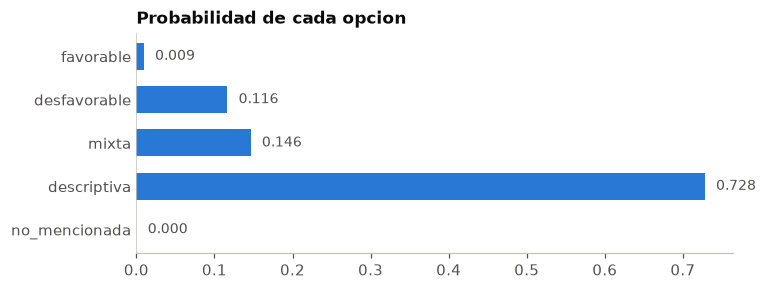

In [5]:
utils.dibujar_probabilidades(respuesta, "Probabilidad de cada opcion")

> **Para mirar.**
>
> - La respuesta es un nombre de la lista y cinco probabilidades que suman 1. No hay texto que interpretar: el programa puede usar `respuesta["choice"]` directamente.
> - La decisión es discutible. La reseña elogia la fotografía, pero `favorable` quedó con 0,009 y el modelo eligió `descriptiva` con 0,73.
> - Que una opción tenga 0,73 no quiere decir que la respuesta sea correcta en ese porcentaje de los casos. Si esa cifra merece confianza, hay que medirlo (sección 5).

## 2. Abrir el mecanismo

| | Modelo de lenguaje (unidades 012 a 015) | Modelo de decisión |
|---|---|---|
| Qué produce | Texto, token por token, elegido entre todo su vocabulario | Un puntaje para cada opción que le damos |
| Forma de la salida | Hay que pedirla y validarla (unidad 013) | Viene con la forma de la pregunta |
| Duda | No la informa | Una probabilidad por opción |
| Trabajo | Una pasada del modelo por cada token que escribe | Una sola pasada |

Julia es un **codificador**, como BERT (unidades 010 y 011). Lee el estado, la pregunta y las opciones juntos, en una sola secuencia, y una **cabeza de decisión** agregada sobre el codificador da un número para cada opción. Ese número se llama **logit** o puntaje: puede ser negativo y los de todas las opciones no suman nada en particular.

Para convertir los puntajes en probabilidades se usa **softmax**: se aplica la exponencial a cada puntaje y cada resultado se divide por la suma de todos. `modelo.logits` devuelve los puntajes antes de ese paso.

In [6]:
fila = {
    "state": texto,
    "question": preguntas["fotografia"]["instructions"],
    "type": "choice",
    "options": list(preguntas["fotografia"]["criteria"].values()),
}
puntajes = modelo.logits([fila])[0]

opciones = list(preguntas["fotografia"]["criteria"].keys())
for opcion, puntaje in zip(opciones, puntajes):
    print(f"{opcion:>14}: {puntaje:6.2f}")

     favorable:  -1.34
  desfavorable:   1.18
         mixta:   1.41
   descriptiva:   3.01
 no_mencionada:  -6.18


> **Para mirar.** `descriptiva` tiene el puntaje más alto (3,01) y `no_mencionada` el más bajo (−6,18). Lo que importa son las diferencias entre los puntajes: si a los cinco se les sumara el mismo número, ni la decisión ni las probabilidades cambiarían.

### Microlaboratorio 1 — De puntajes a probabilidades

**Tarea.** Hacer a mano la cuenta de softmax con los cinco puntajes de la reseña.
**Producto.** Una lista `mis_probabilidades` igual a las probabilidades que devolvió el modelo.
**Antes de empezar.** Secciones 1 y 2.

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `exponencial` | la exponencial del puntaje | `math.exp(puntaje)` |
| (2) `probabilidad` | la exponencial dividida por la suma de todas | `exponencial` y `total` |

**Comprobación.** Cada probabilidad tiene que coincidir con la de `respuesta["probabilities"]` (con una diferencia menor que 0,001) y las cinco tienen que sumar 1.

> **Ayuda 1.** `math.exp(2)` es *e* elevado a la 2, unos 7,39. La exponencial convierte cualquier número, aunque sea negativo, en uno positivo.
> **Ayuda 2.** `total` ya está calculado con todas las exponenciales: en la línea (2) solo hay que dividir.

In [7]:
exponenciales = []
for puntaje in puntajes:
    exponencial = 0.0  # COMPLETAR (1)
    exponenciales.append(exponencial)

total = sum(exponenciales)

mis_probabilidades = []
for exponencial in exponenciales:
    probabilidad = 0.0  # COMPLETAR (2)
    mis_probabilidades.append(probabilidad)

for opcion, probabilidad in zip(opciones, mis_probabilidades):
    print(f"{opcion:>14}: {probabilidad:.4f}")

     favorable: 0.0000
  desfavorable: 0.0000
         mixta: 0.0000
   descriptiva: 0.0000
 no_mencionada: 0.0000


In [8]:
coinciden = True
for opcion, probabilidad in zip(opciones, mis_probabilidades):
    if abs(probabilidad - respuesta["probabilities"][opcion]) > 0.001:
        coinciden = False

utils.comprobar(
    coinciden and abs(sum(mis_probabilidades) - 1) < 0.001,
    "revisa la exponencial (1) y la division por el total (2).",
)

Todavia no: revisa la exponencial (1) y la division por el total (2).


### La descripción es parte de la pregunta

El modelo no sabe qué quiere decir `favorable`: lee la descripción. Cambiamos solo la descripción de esa opción, para aclarar que la reseña puede criticar otra cosa, y repetimos la pregunta con la misma reseña. Es lo mismo que pasaba con la descripción de una herramienta en la unidad 015.

In [9]:
criterios_v2 = dict(preguntas["fotografia"]["criteria"])
criterios_v2["favorable"] = (
    "Elogia la fotografía o su calidad visual, aunque critique otros "
    "aspectos como el guion."
)
pregunta_v2 = dict(preguntas["fotografia"])
pregunta_v2["criteria"] = criterios_v2

resultado_v2 = modelo.predict(
    state=texto, questions={"fotografia": pregunta_v2}
)
respuesta_v2 = resultado_v2["answers"]["fotografia"]

comparacion_descripciones = pd.DataFrame({
    "original": respuesta["probabilities"],
    "descripcion nueva": respuesta_v2["probabilities"],
})
print("Decision con la descripcion nueva:", respuesta_v2["choice"])
comparacion_descripciones.round(3)

Decision con la descripcion nueva: mixta


,original,descripcion nueva
favorable,0.009,0.319
desfavorable,0.116,0.024
mixta,0.146,0.331
descriptiva,0.728,0.326
no_mencionada,0.000,0.000


> **Para mirar.** `favorable` subió de 0,009 a 0,32, pero el modelo quedó repartido entre tres opciones (0,32, 0,33 y 0,33) y ganó `mixta`. Cambiar una descripción cambia la decisión; que la mejore no está garantizado, y solo se sabe probando.

## 3. Tres tipos de pregunta, combinados en el código

| Tipo | Qué pregunta | Qué devuelve |
|---|---|---|
| `choice` | Cuál de estas opciones corresponde | `choice`, la opción ganadora, y una probabilidad por opción |
| `score` | Qué nivel de una escala ordenada corresponde | `score`, el nivel esperado (puede tener decimales, de 0 al último nivel) |
| `noul` | Si una afirmación es verdadera | `noul`, la probabilidad de que lo sea |

Varias preguntas van en una sola llamada, y el modelo responde cada una por separado. La documentación de TypeSafe recomienda preguntas **atómicas**: en lugar de «¿es buena esta reseña?», preguntar por cada aspecto y combinar las respuestas en el código, con pesos que decide quien programa y que se pueden cambiar sin tocar las preguntas.

`escala` arma una pregunta de tipo `score` con cinco niveles, del 0 («Muy mal») al 4 («Muy bien»).

In [10]:
def escala(aspecto: str) -> dict:
    """Arma una pregunta de tipo score sobre un aspecto de la pelicula.

    Args:
        aspecto: Lo que se valora, por ejemplo "la fotografía".

    Returns:
        Pregunta con cinco niveles ordenados, de 0 (peor) a 4 (mejor).
    """
    return {
        "type": "score",
        "instructions": f"¿Cómo valora el texto {aspecto}?",
        "criteria": [
            "Muy mal",
            "Mal",
            "Ni bien ni mal, o no lo menciona",
            "Bien",
            "Muy bien",
        ],
    }


preguntas_combinadas = {
    "fotografia": preguntas["fotografia"],
    "nivel_fotografia": escala("la fotografía"),
    "nivel_guion": escala("el guion"),
    "opina_del_guion": {
        "type": "noul",
        "instructions": "¿El texto opina sobre el guion?",
        "criteria": {
            "false": "No opina sobre el guion.",
            "true": "Opina sobre el guion, a favor o en contra.",
        },
    },
}

In [11]:
resena = (
    "Actuaciones enormes y un guion redondo; "
    "lástima que la imagen sea tan chata."
)
respuestas = modelo.predict(
    state=resena, questions=preguntas_combinadas
)["answers"]

filas_por_tipo = []
for nombre, contestacion in respuestas.items():
    if contestacion["type"] == "choice":
        valor = contestacion["choice"]
    elif contestacion["type"] == "score":
        valor = round(contestacion["score"], 2)
    else:
        valor = round(contestacion["noul"], 3)
    filas_por_tipo.append({
        "pregunta": nombre,
        "tipo": contestacion["type"],
        "respuesta": valor,
    })

pd.DataFrame(filas_por_tipo)

,pregunta,tipo,respuesta
0,fotografia,choice,mixta
1,nivel_fotografia,score,1.48
2,nivel_guion,score,1.31
3,opina_del_guion,noul,0.985


Un sitio de crítica quiere ordenar reseñas para su sección de fotografía. Combina los dos niveles con pesos propios: 70 % la fotografía y 30 % el guion, cada nivel llevado a una escala de 0 a 1 (se divide por 4, el nivel más alto).

In [12]:
pesos = {"nivel_fotografia": 0.7, "nivel_guion": 0.3}

puntaje_compuesto = 0.0
for nombre, peso in pesos.items():
    nivel = respuestas[nombre]["score"]
    puntaje_compuesto = puntaje_compuesto + peso * nivel / 4

print(f"Puntaje compuesto: {puntaje_compuesto:.2f} (de 0 a 1)")

Puntaje compuesto: 0.36 (de 0 a 1)


> **Para mirar.**
>
> - Las cuatro respuestas salieron de una sola llamada, cada una con su tipo: un nombre, dos niveles y una probabilidad.
> - La reseña elogia el guion («redondo»), y el nivel del guion dio 1,31: entre «Mal» y «Ni bien ni mal». La imagen «chata» recibió 1,48, casi lo mismo.
> - La cuenta del puntaje compuesto está bien hecha, pero sobre respuestas que no reflejan la reseña. La composición la controla el programa; la calidad de cada respuesta depende del modelo.

## 4. Ponerlo a prueba

Las ocho reseñas, cada una con la valoración que propone el docente. Las seis primeras son las de la versión original de este cuaderno.

In [13]:
casos = [
    ("La fotografía es hermosa, pero el guion es insoportable.",
     "favorable"),
    ("La iluminación es horrible y los encuadres son un desastre.",
     "desfavorable"),
    ("Los interiores tienen una luz preciosa, pero los exteriores se "
     "ven espantosos.", "mixta"),
    ("La película está filmada en blanco y negro.",
     "descriptiva"),
    ("Los diálogos son brillantes y la historia es atrapante.",
     "no_mencionada"),
    ("Qué maravilla de fotografía: no se ve absolutamente nada.",
     "desfavorable"),
    ("Actuaciones enormes y un guion redondo; lástima que la imagen "
     "sea tan chata.", "desfavorable"),
    ("Cada plano parece un cuadro, aunque la historia no va a "
     "ningún lado.", "favorable"),
]

filas = []
respuestas_julia = []
for texto_del_caso, referencia in casos:
    inicio = time.perf_counter()
    resultado = modelo.predict(state=texto_del_caso, questions=preguntas)
    demora = time.perf_counter() - inicio
    contestacion = resultado["answers"]["fotografia"]
    respuestas_julia.append(contestacion)
    filas.append({
        "texto": texto_del_caso,
        "referencia": referencia,
        "julia": contestacion["choice"],
        "coincide": contestacion["choice"] == referencia,
        "probabilidad": round(contestacion["max_probability"], 3),
        "ms": round(demora * 1000),
    })

tabla_julia = pd.DataFrame(filas)
print("Coincidencias:", tabla_julia["coincide"].sum(), "de", len(casos))
tabla_julia

Coincidencias: 4 de 8


,texto,referencia,julia,coincide,probabilidad,ms
0,"La fotografía es hermosa, pero el guion es insoportable.",favorable,descriptiva,False,0.728,27
1,La iluminación es horrible y los encuadres son un desastre.,desfavorable,desfavorable,True,0.719,26
2,"Los interiores tienen una luz preciosa, pero los exteriores se ven espantosos.",mixta,mixta,True,0.843,26
3,La película está filmada en blanco y negro.,descriptiva,descriptiva,True,0.933,26
4,Los diálogos son brillantes y la historia es atrapante.,no_mencionada,mixta,False,0.670,26
5,Qué maravilla de fotografía: no se ve absolutamente nada.,desfavorable,desfavorable,True,0.459,26
6,Actuaciones enormes y un guion redondo; lástima que la imagen sea tan chata.,desfavorable,mixta,False,0.885,26
7,"Cada plano parece un cuadro, aunque la historia no va a ningún lado.",favorable,descriptiva,False,0.812,26


> **Para mirar.**
>
> - 4 de 8 coincidencias, y cada respuesta tardó unos 26 milisegundos.
> - La ironía (fila 6) salió bien, con la probabilidad más baja de la tabla (0,46): el modelo dudó.
> - Los errores no avisan. «Actuaciones enormes...» quedó en `mixta` con 0,885, más que varias respuestas correctas. Y «Los diálogos son brillantes...», que no habla de la imagen, quedó en `mixta`.
> - Con ocho casos esto no estima el desempeño del modelo: muestra los tipos de error que hay que buscar con más casos.

## 5. Una compuerta por confianza

Una probabilidad sola es difícil de comparar entre preguntas: 0,5 es poco con dos opciones y mucho con diez. TypeSafe resume cada respuesta de tipo `choice` en una **confianza** de 0 a 1:

$$\text{confianza} = \frac{p_{\max} - 1/n}{1 - 1/n}$$

donde $p_{\max}$ es la probabilidad de la opción elegida y $n$ la cantidad de opciones. Vale 0 cuando las opciones están empatadas y 1 cuando toda la probabilidad está en una sola.

La documentación propone usarla como **compuerta**: con confianza alta, el programa actúa solo; con confianza baja, el caso pasa a una persona. El umbral depende de lo que cuesta equivocarse.

### Microlaboratorio 2 — La compuerta

**Tarea.** Escribir la confianza y una función que decide si una respuesta se usa sola o pasa a revisión.
**Producto.** `confianza` y `decidir`, comprobadas con probabilidades conocidas.
**Antes de empezar.** Secciones 4 y 5.

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `return` de `confianza` | la fórmula de arriba | `maxima` y `n` |
| (2) condición del `if` | que la confianza alcance el umbral | `confianza(respuesta["probabilities"])`, `>=` y `umbral` |

**Comprobación.** Con probabilidades 0,6, 0,3 y 0,1, la confianza es 0,4 (es el ejemplo de la documentación de TypeSafe). Una respuesta con 0,95 en una opción pasa la compuerta de 0,6 y una con todas las opciones empatadas va a revisión.

> **Ayuda 1.** Con tres opciones, $1/n$ es un tercio: `1 / n`. Revisá los paréntesis del numerador y del denominador.
> **Ayuda 2.** La condición tiene que dar `True` cuando la respuesta se puede usar sola.

In [14]:
def confianza(probabilidades: dict) -> float:
    """Calcula la confianza de una respuesta de tipo choice.

    Args:
        probabilidades: Diccionario de opcion a probabilidad.

    Returns:
        0 si las opciones estan empatadas, 1 si una tiene todo.
    """
    n = len(probabilidades)
    maxima = max(probabilidades.values())
    return 0.0  # COMPLETAR (1)


def decidir(respuesta: dict, umbral: float) -> str:
    """Usa la respuesta del modelo solo si la confianza alcanza el umbral.

    Args:
        respuesta: Respuesta de tipo choice, con "choice" y
            "probabilities".
        umbral: Confianza minima para actuar sin una persona.

    Returns:
        La opcion elegida, o "revision_humana".
    """
    if False:  # COMPLETAR (2)
        return respuesta["choice"]
    return "revision_humana"

In [15]:
ejemplo = {"a": 0.6, "b": 0.3, "c": 0.1}
segura = {
    "choice": "a",
    "probabilities": {"a": 0.95, "b": 0.03, "c": 0.02},
}
empatada = {
    "choice": "a",
    "probabilities": {"a": 1 / 3, "b": 1 / 3, "c": 1 / 3},
}

utils.comprobar(
    abs(confianza(ejemplo) - 0.4) < 0.001
    and decidir(segura, 0.6) == "a"
    and decidir(empatada, 0.6) == "revision_humana",
    "revisa la formula (1) y la condicion del if (2).",
)

Todavia no: revisa la formula (1) y la condicion del if (2).


Con la compuerta lista, la aplicamos a las ocho reseñas con varios umbrales. Para cada umbral, la **cobertura** es cuántas reseñas decide el programa solo, y la última columna dice cuántas de esas coinciden con la referencia. Si el microlaboratorio no está resuelto, todas van a revisión.

In [16]:
umbrales = [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]

filas_umbral = []
for umbral in umbrales:
    decididas = 0
    correctas = 0
    for contestacion, caso in zip(respuestas_julia, casos):
        decision = decidir(contestacion, umbral)
        if decision != "revision_humana":
            decididas = decididas + 1
            if decision == caso[1]:
                correctas = correctas + 1
    filas_umbral.append({
        "umbral": umbral,
        "decide solo": decididas,
        "pasan a una persona": len(casos) - decididas,
        "decididas que coinciden": correctas,
    })

pd.DataFrame(filas_umbral)

,umbral,decide solo,pasan a una persona,decididas que coinciden
0,0.0,0,8,0
1,0.5,0,8,0
2,0.6,0,8,0
3,0.7,0,8,0
4,0.8,0,8,0
5,0.9,0,8,0


> **Para mirar.**
>
> - Con umbral 0 el programa decide las ocho y coinciden 4. Con 0,8 decide 3 y coinciden 2: la reseña de las actuaciones (confianza 0,86) pasa sola con una respuesta equivocada. Con 0,9 decide una sola. Para evitar los errores, casi todo termina en manos de una persona.
> - La compuerta no arregla al modelo: elige qué casos se le confían. Para que funcione, una probabilidad alta tiene que corresponder a acertar más seguido, es decir, el modelo tiene que estar **calibrado**. Con este modelo y estas reseñas no lo está, y eso solo se ve con casos que tienen referencia.
> - Es lo que mide `jev-benchmarks`, la evaluación con la que se comparan Jev y Julia: cuánto trabajo se puede automatizar sin pasar un margen de error.

## 6. Un modelo de lenguaje con las mismas reseñas

Hacemos la misma pregunta a `granite4` (unidades 013 a 015), con una salida estructurada como la de la unidad 013: el esquema solo admite las cinco opciones. Si Ollama no está disponible, la sección se saltea y el resto del cuaderno funciona igual.

In [17]:
descripciones = ""
for nombre, descripcion in preguntas["fotografia"]["criteria"].items():
    descripciones = descripciones + f"- {nombre}: {descripcion}\n"

esquema = {
    "type": "object",
    "properties": {
        "valoracion": {
            "type": "string",
            "enum": list(preguntas["fotografia"]["criteria"].keys()),
        },
    },
    "required": ["valoracion"],
}


def preguntar_al_modelo_de_lenguaje(texto_de_la_resena: str) -> str:
    """Hace la pregunta de la fotografia a granite4 con salida fija.

    Args:
        texto_de_la_resena: La resena que hay que valorar.

    Returns:
        El nombre de la opcion que eligio el modelo.
    """
    pedido = (
        preguntas["fotografia"]["instructions"]
        + "\n\nOpciones:\n" + descripciones
        + "\nTexto: " + texto_de_la_resena
    )
    respuesta_llm = ollama.chat(
        model=utils.MODELO_LOCAL,
        messages=[{"role": "user", "content": pedido}],
        format=esquema,               # solo admite las cinco opciones
        options={"temperature": 0},   # la misma salida en cada ejecucion
    )
    return json.loads(respuesta_llm.message.content)["valoracion"]

In [18]:
if utils.ollama_disponible():
    preguntar_al_modelo_de_lenguaje("Una prueba.")  # carga el modelo
    filas_llm = []
    for texto_del_caso, referencia in casos:
        inicio = time.perf_counter()
        eleccion = preguntar_al_modelo_de_lenguaje(texto_del_caso)
        demora = time.perf_counter() - inicio
        filas_llm.append({
            "granite4": eleccion,
            "coincide granite4": eleccion == referencia,
            "ms granite4": round(demora * 1000),
        })
    comparacion = pd.concat(
        [tabla_julia[["texto", "referencia", "julia", "coincide", "ms"]],
         pd.DataFrame(filas_llm)],
        axis=1,
    )
    print(
        "Coincidencias: Julia", comparacion["coincide"].sum(),
        "- granite4", comparacion["coincide granite4"].sum(),
    )
    display(comparacion)

Ollama responde y tiene granite4:latest.


Coincidencias: Julia 4 - granite4 5


,texto,referencia,julia,coincide,ms,granite4,coincide granite4,ms granite4
0,"La fotografía es hermosa, pero el guion es insoportable.",favorable,descriptiva,False,27,favorable,True,514
1,La iluminación es horrible y los encuadres son un desastre.,desfavorable,desfavorable,True,26,desfavorable,True,548
2,"Los interiores tienen una luz preciosa, pero los exteriores se ven espantosos.",mixta,mixta,True,26,desfavorable,False,549
3,La película está filmada en blanco y negro.,descriptiva,descriptiva,True,26,descriptiva,True,549
4,Los diálogos son brillantes y la historia es atrapante.,no_mencionada,mixta,False,26,descriptiva,False,542
5,Qué maravilla de fotografía: no se ve absolutamente nada.,desfavorable,desfavorable,True,26,desfavorable,True,540
6,Actuaciones enormes y un guion redondo; lástima que la imagen sea tan chata.,desfavorable,mixta,False,26,desfavorable,True,544
7,"Cada plano parece un cuadro, aunque la historia no va a ningún lado.",favorable,descriptiva,False,26,desfavorable,False,541


> **Para mirar.**
>
> - `granite4` coincidió en 5 y Julia en 4, pero no en las mismas: `granite4` acertó la primera reseña y la de las actuaciones, y falló la mixta. Tardó unos 540 ms por reseña, unas 20 veces más que Julia (26 ms).
> - `granite4` no da probabilidades: cuando se equivoca, no hay ninguna señal para mandar el caso a una persona.
> - Con ocho casos, la diferencia entre los dos modelos no alcanza para decir cuál es mejor.

## 7. Decidir cómo usarlo

| | Jev (TypeSafe) | Julia-1 (Supersonic Labs) | Modelo de lenguaje (`granite4`) |
|---|---|---|---|
| Acceso | Servicio pago: se cobra por token de entrada y los textos viajan a un servidor externo | Gratuito, Apache 2.0, corre en la computadora | Gratuito, corre en la computadora con Ollama |
| Tipos de pregunta | `choice`, `score`, `noul` y `box` (ubicar algo en una imagen) | `choice`, `score` y `noul` | Lo que se le pida, validado después |
| Probabilidades | Sí, más una confianza ya calculada | Sí; la confianza se calcula (sección 5) | No |
| Entrenamiento | Aprendizaje por refuerzo para que las probabilidades estén calibradas (RLCD, según TypeSafe) | Codificador mmBERT-small con una cabeza de decisión, entrenado con ejemplos en formato de decisión | Generar texto que la gente prefiere |
| Lo que vimos acá | No se probó: hace falta una clave paga | Rápido, pero con errores seguros en estas reseñas | Más lento, sin señal de duda |

**Patrones de uso** que propone la documentación de TypeSafe ([docs.typesafe.ai](https://docs.typesafe.ai/patterns)):

| Patrón | Qué hace | Dónde ya lo vimos |
|---|---|---|
| Enrutar por intención | Clasificar cada pedido y mandarlo a código fijo, a un modelo de lenguaje especializado o a una persona | La elección de herramienta del agente (unidad 015) |
| Compuerta por confianza | Actuar solo con confianza alta; si no, preguntar o derivar | La aprobación humana (unidades 015 y 017) |
| Puntaje compuesto | Preguntas atómicas combinadas con pesos en el código | Sección 3 |
| Revisar a un modelo de lenguaje | Preguntar si una respuesta está respaldada por la fuente, o si un mensaje es riesgoso, antes de mostrarlo | Responder con fuentes (unidad 014) |

**Una decisión condicional.**

- Un modelo de decisión es razonable cuando:
  - la pregunta tiene opciones cerradas;
  - el programa necesita la respuesta rápido o para muchos textos;
  - se comprobó, con casos propios que tienen referencia, que sus probabilidades separan los aciertos de los errores.
- Julia-1 sirve para entender la arquitectura y la interfaz. Para valorar reseñas en español no alcanzó: no lo usaríamos para decidir sin una persona.
- Jev promete probabilidades calibradas, a cambio de pagar y de enviar los textos a un servicio externo. Esa promesa también se mide antes de confiar en ella.

## Probá con tu reseña

Cambiá el texto y volvé a ejecutar la celda. Probá una reseña que elogie la fotografía sin decir «fotografía», y otra que hable solo de la música.

In [19]:
mi_resena = "Los colores del atardecer en la playa me dejaron sin aire."

respuesta_propia = modelo.predict(
    state=mi_resena, questions=preguntas
)["answers"]["fotografia"]

print("Decision:", respuesta_propia["choice"])
print(f"Confianza: {confianza(respuesta_propia['probabilities']):.2f}")
utils.tabla_de_probabilidades(respuesta_propia)

Decision: mixta
Confianza: 0.00


,opcion,probabilidad
0,mixta,0.8481
1,descriptiva,0.1349
2,desfavorable,0.0134
3,favorable,0.0035
4,no_mencionada,0.0000


## Qué te llevás

- Un modelo de decisión no escribe: da un puntaje a cada opción que define el programa, y softmax lo convierte en probabilidades. Las descripciones de las opciones son parte de la pregunta.
- Las preguntas atómicas se combinan en el código, y una compuerta por confianza decide qué casos resuelve el programa y cuáles pasan a una persona.
- Una probabilidad no es una garantía: si el modelo no está calibrado para tus textos, la compuerta deja pasar errores seguros. Se mide con casos propios antes de usarlo.

**Qué sigue.** En `017_laboratorio_de_agentes`, un agente que actúa en nombre de una persona y las defensas que dependen del código y no del modelo.